In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../results/video_test/student_data.csv")

df.head()

,frame,time,student_id,yaw,pitch,roll,left_ear,right_ear,avg_ear,eye_state,gaze,torso_angle,left_knee_angle,right_knee_angle
0,1,0.000,1,-40.641,8.809,-1.755,0.3026,0.2581,0.2803,Open,RIGHT,2.122,65.488,13.286
1,1,0.000,2,NaN,NaN,NaN,0.6084,0.2995,0.4540,Open,NaN,2.938,70.735,48.893
2,1,0.000,3,27.458,7.223,10.621,0.1961,0.1497,0.1729,CLOSED,LEFT,3.906,153.979,72.863
3,1,0.000,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.453,108.452,124.424
4,2,0.033,1,-40.641,8.809,-1.755,0.3026,0.2581,0.2803,Open,RIGHT,2.111,65.425,13.213


In [3]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Shape: (940, 14)

Columns:
['frame', 'time', 'student_id', 'yaw', 'pitch', 'roll', 'left_ear', 'right_ear', 'avg_ear', 'eye_state', 'gaze', 'torso_angle', 'left_knee_angle', 'right_knee_angle']

Data types:
frame                 int64
time                float64
student_id            int64
yaw                 float64
pitch               float64
roll                float64
left_ear            float64
right_ear           float64
avg_ear             float64
eye_state               str
gaze                    str
torso_angle         float64
left_knee_angle     float64
right_knee_angle    float64
dtype: object


In [4]:
missing_by_student = (
    df.groupby("student_id")
      .apply(lambda x: x.isna().sum())
)

missing_by_student

,frame,time,yaw,pitch,roll,left_ear,right_ear,avg_ear,eye_state,gaze,torso_angle,left_knee_angle,right_knee_angle
student_id,,,,,,,,,,,,,
1,0,0,145,145,145,104,104,104,104,145,0,0,0
2,0,0,123,123,123,68,68,68,68,123,5,5,5
3,0,0,34,34,34,29,29,29,29,34,7,7,7
4,0,0,74,74,74,70,70,70,70,74,9,9,9
6,0,0,4,4,4,0,0,0,0,4,6,6,6
8,0,0,1,1,1,1,1,1,1,1,1,1,1
9,0,0,15,15,15,5,5,5,5,15,34,34,34
12,0,0,8,8,8,6,6,6,6,8,10,10,10
17,0,0,16,16,16,13,13,13,13,16,1,1,1


In [5]:
features = [
    "yaw",
    "pitch",
    "roll",
    "avg_ear",
    "gaze",
    "torso_angle",
    "left_knee_angle",
    "right_knee_angle"
]

availability = (
    df.groupby("student_id")[features]
      .apply(lambda x: x.notna().mean() * 100)
      .round(2)
)

availability

,yaw,pitch,roll,avg_ear,gaze,torso_angle,left_knee_angle,right_knee_angle
student_id,,,,,,,,
1,43.80,43.80,43.80,59.69,43.80,100.00,100.00,100.00
2,51.76,51.76,51.76,73.33,51.76,98.04,98.04,98.04
3,68.22,68.22,68.22,72.90,68.22,93.46,93.46,93.46
4,27.45,27.45,27.45,31.37,27.45,91.18,91.18,91.18
6,33.33,33.33,33.33,100.00,33.33,0.00,0.00,0.00
8,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
9,55.88,55.88,55.88,85.29,55.88,0.00,0.00,0.00
12,20.00,20.00,20.00,40.00,20.00,0.00,0.00,0.00
17,0.00,0.00,0.00,18.75,0.00,93.75,93.75,93.75


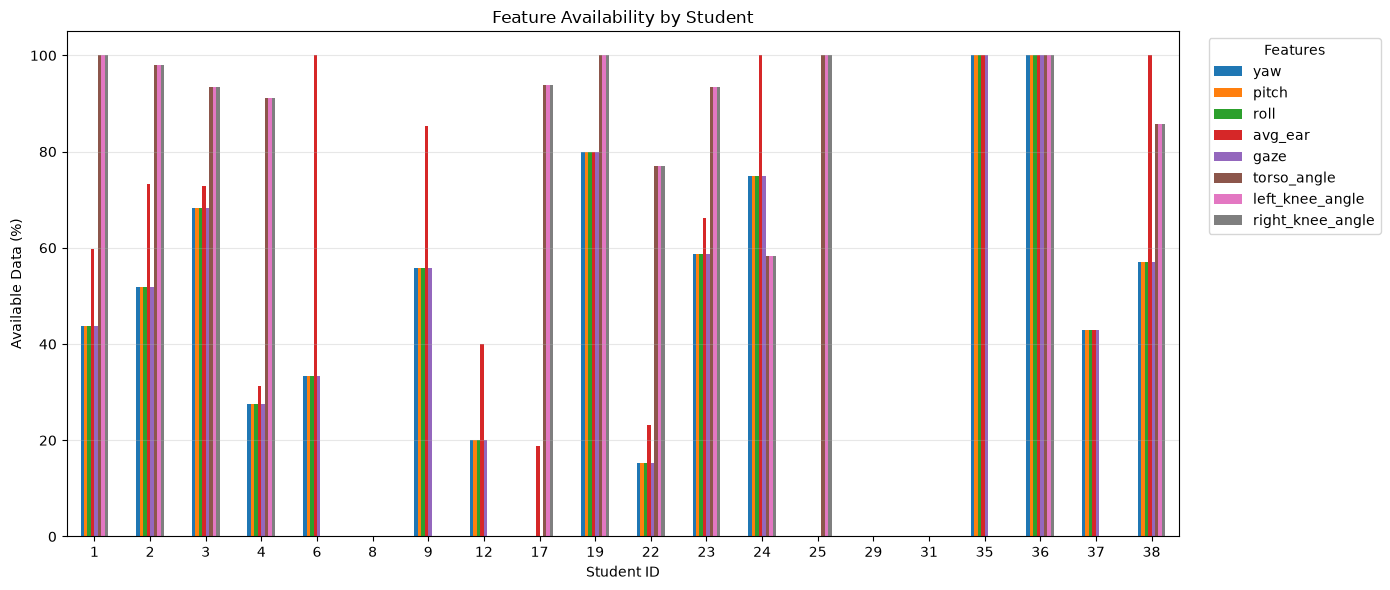

In [6]:
availability.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Feature Availability by Student")
plt.xlabel("Student ID")
plt.ylabel("Available Data (%)")
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.legend(
    title="Features",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

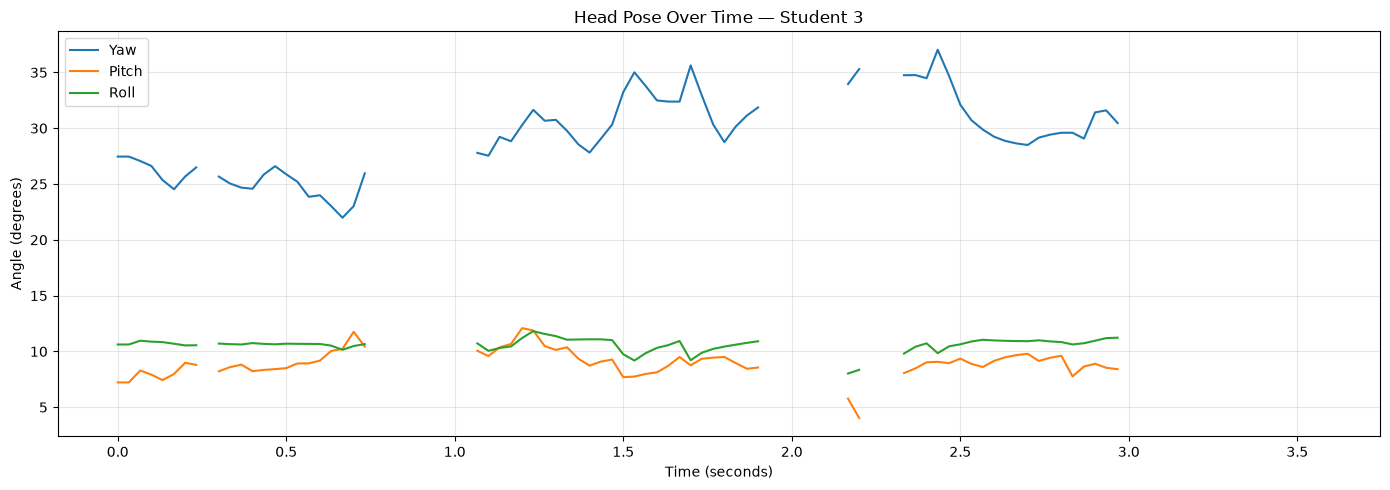

In [25]:
student_id = 3

student = df[df["student_id"] == student_id]

plt.figure(figsize=(14, 5))

plt.plot(student["time"], student["yaw"], label="Yaw")
plt.plot(student["time"], student["pitch"], label="Pitch")
plt.plot(student["time"], student["roll"], label="Roll")

plt.xlabel("Time (seconds)")
plt.ylabel("Angle (degrees)")
plt.title(f"Head Pose Over Time — Student {student_id}")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

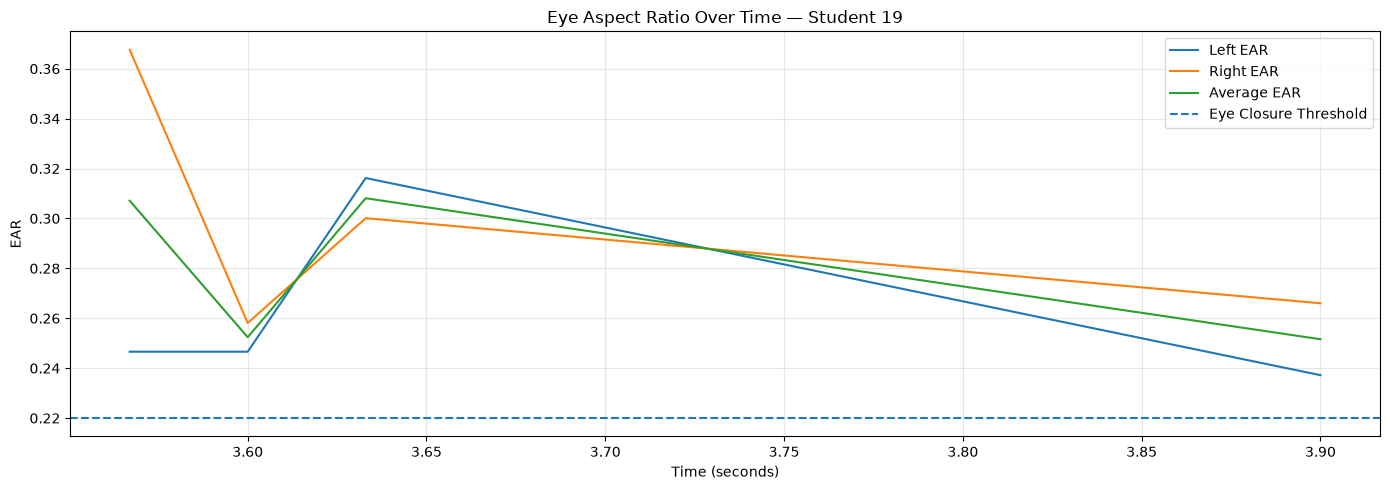

In [24]:
student_id = 19

student = df[df["student_id"] == student_id]

plt.figure(figsize=(14, 5))

plt.plot(student["time"], student["left_ear"], label="Left EAR")
plt.plot(student["time"], student["right_ear"], label="Right EAR")
plt.plot(student["time"], student["avg_ear"], label="Average EAR")

plt.axhline(
    y=0.22,
    linestyle="--",
    label="Eye Closure Threshold"
)

plt.xlabel("Time (seconds)")
plt.ylabel("EAR")
plt.title(f"Eye Aspect Ratio Over Time — Student {student_id}")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

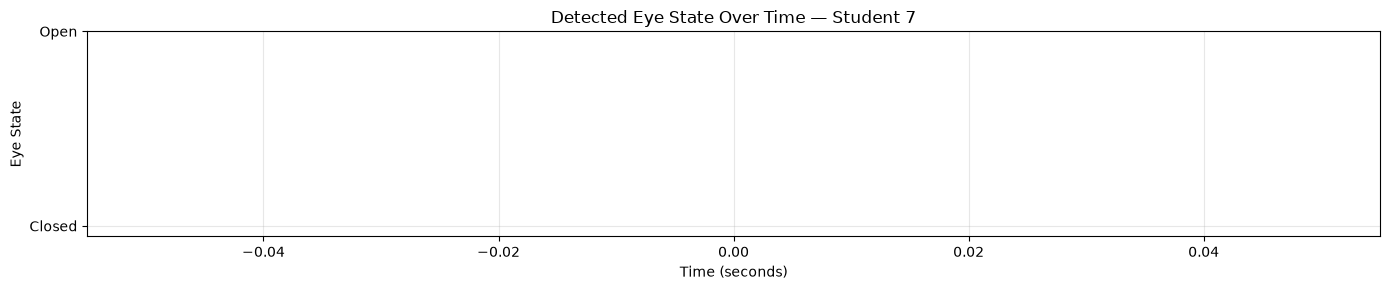

In [9]:
student_id = 7

student = df[df["student_id"] == student_id].copy()

eye_state_numeric = student["eye_state"].map({
    "Open": 1,
    "OPEN": 1,
    "Closed": 0,
    "CLOSED": 0
})

plt.figure(figsize=(14, 3))

plt.step(
    student["time"],
    eye_state_numeric,
    where="post"
)

plt.yticks([0, 1], ["Closed", "Open"])
plt.xlabel("Time (seconds)")
plt.ylabel("Eye State")
plt.title(f"Detected Eye State Over Time — Student {student_id}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
gaze_counts = (
    df.groupby(["student_id", "gaze"])
      .size()
      .unstack(fill_value=0)
)

gaze_percentage = (
    gaze_counts
    .div(gaze_counts.sum(axis=1), axis=0)
    .mul(100)
    .round(2)
)

gaze_percentage

gaze,DOWN,FORWARD,LEFT,RIGHT,UP
student_id,,,,,
1,0.00,14.16,0.00,85.84,0.00
2,3.03,52.27,22.73,21.97,0.00
3,0.00,0.00,100.00,0.00,0.00
4,0.00,32.14,67.86,0.00,0.00
6,0.00,0.00,100.00,0.00,0.00
9,0.00,78.95,0.00,15.79,5.26
12,0.00,0.00,0.00,100.00,0.00
19,0.00,0.00,100.00,0.00,0.00
22,0.00,0.00,100.00,0.00,0.00


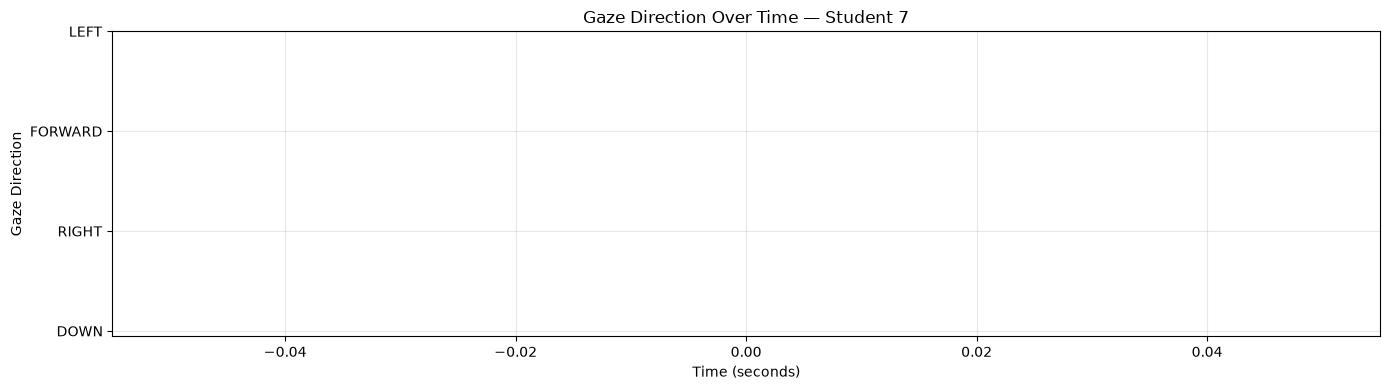

In [11]:
student_id = 7

student = df[df["student_id"] == student_id].copy()

gaze_mapping = {
    "DOWN": 0,
    "RIGHT": 1,
    "FORWARD": 2,
    "LEFT": 3
}

student["gaze_numeric"] = student["gaze"].map(gaze_mapping)

plt.figure(figsize=(14, 4))

plt.step(
    student["time"],
    student["gaze_numeric"],
    where="post"
)

plt.yticks(
    [0, 1, 2, 3],
    ["DOWN", "RIGHT", "FORWARD", "LEFT"]
)

plt.xlabel("Time (seconds)")
plt.ylabel("Gaze Direction")
plt.title(f"Gaze Direction Over Time — Student {student_id}")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

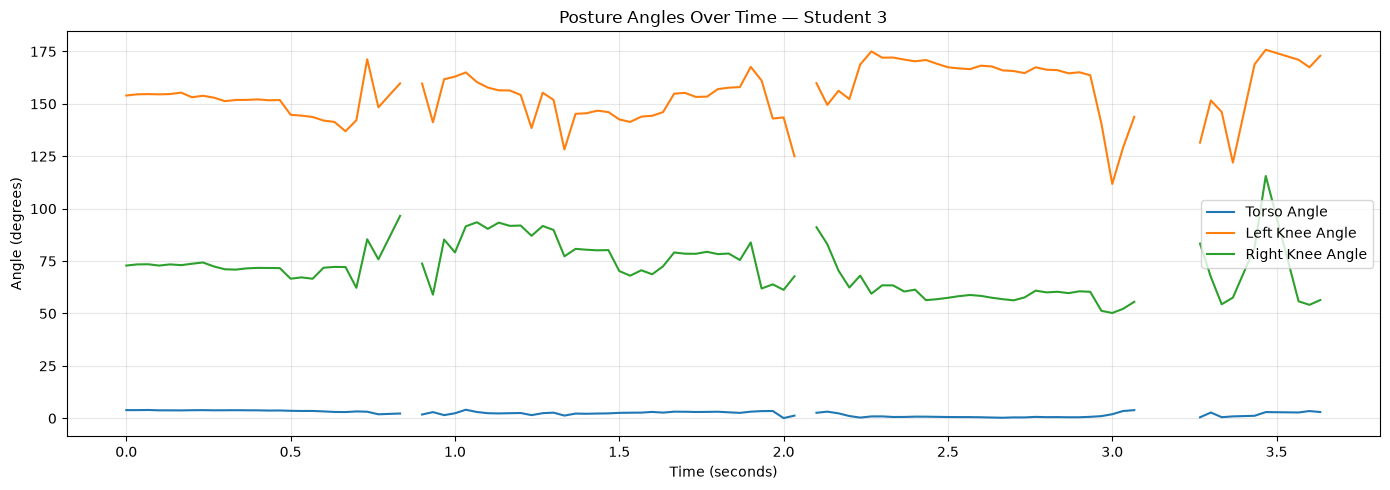

In [12]:
student_id = 3

student = df[df["student_id"] == student_id]

plt.figure(figsize=(14, 5))

plt.plot(
    student["time"],
    student["torso_angle"],
    label="Torso Angle"
)

plt.plot(
    student["time"],
    student["left_knee_angle"],
    label="Left Knee Angle"
)

plt.plot(
    student["time"],
    student["right_knee_angle"],
    label="Right Knee Angle"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Angle (degrees)")
plt.title(f"Posture Angles Over Time — Student {student_id}")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

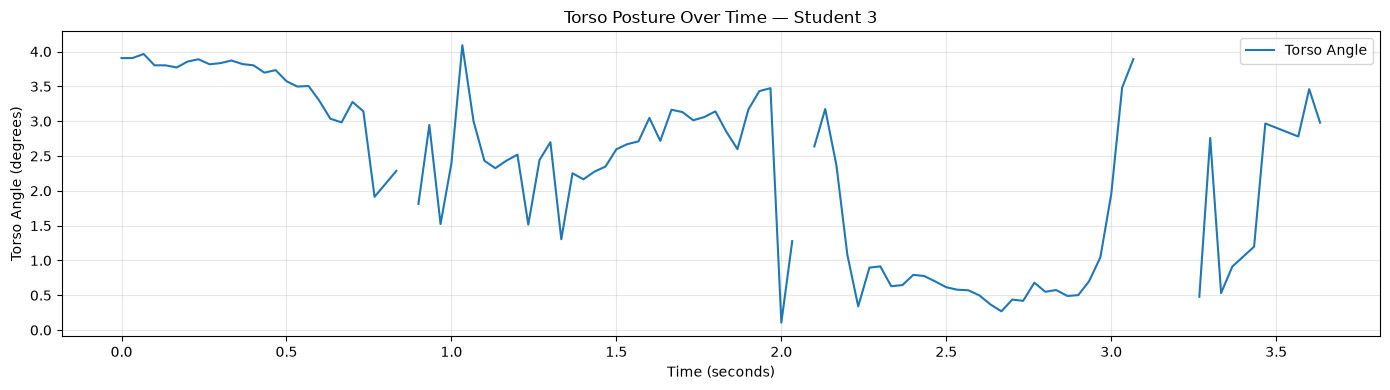

In [13]:
student_id = 3

student = df[df["student_id"] == student_id]

plt.figure(figsize=(14, 4))

plt.plot(
    student["time"],
    student["torso_angle"],
    label="Torso Angle"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Torso Angle (degrees)")
plt.title(f"Torso Posture Over Time — Student {student_id}")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
student_frames = (
    df.groupby("student_id")["frame"]
      .nunique()
      .sort_index()
)

student_frames

student_id
1     258
2     255
3     107
4     102
6       6
8       1
9      34
12     10
17     16
19      5
22     13
23     92
24     12
25      1
29      1
31      2
35      4
36      7
37      7
38      7
Name: frame, dtype: int64

In [15]:
tracking_duration = (
    df.groupby("student_id")
      .agg(
          first_frame=("frame", "min"),
          last_frame=("frame", "max"),
          frames_seen=("frame", "nunique"),
          first_time=("time", "min"),
          last_time=("time", "max")
      )
)

tracking_duration["duration_sec"] = (
    tracking_duration["last_time"] - tracking_duration["first_time"]
)

tracking_duration

,first_frame,last_frame,frames_seen,first_time,last_time,duration_sec
student_id,,,,,,
1,1,258,258,0.000,8.567,8.567
2,1,258,255,0.000,8.567,8.567
3,1,124,107,0.000,4.100,4.100
4,1,105,102,0.000,3.467,3.467
6,10,15,6,0.300,0.467,0.167
8,29,29,1,0.933,0.933,0.000
9,31,95,34,1.000,3.133,2.133
12,71,84,10,2.333,2.767,0.434
17,104,124,16,3.433,4.100,0.667


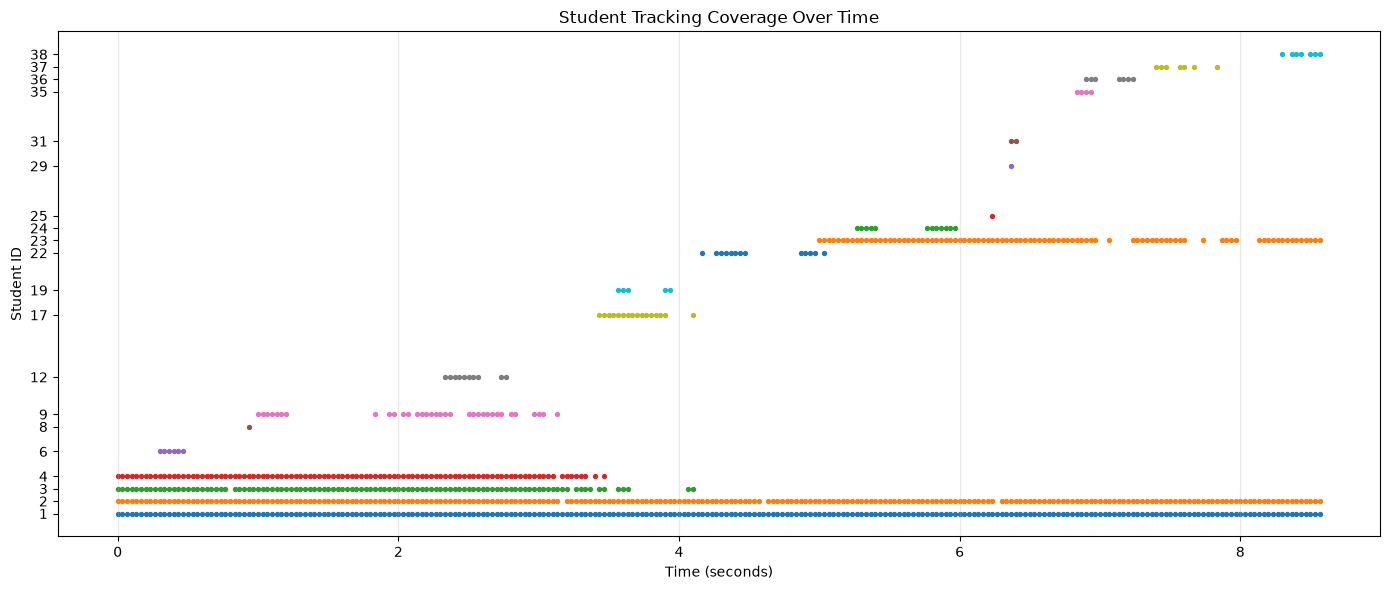

In [16]:
plt.figure(figsize=(14, 6))

for student_id, group in df.groupby("student_id"):
    plt.scatter(
        group["time"],
        [student_id] * len(group),
        s=8
    )

plt.xlabel("Time (seconds)")
plt.ylabel("Student ID")
plt.title("Student Tracking Coverage Over Time")

plt.yticks(sorted(df["student_id"].unique()))
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
gaze_overall = (
    df["gaze"]
    .value_counts(dropna=True)
    .sort_values(ascending=False)
)

gaze_overall

gaze
RIGHT      156
FORWARD    149
LEFT       146
DOWN         4
UP           1
Name: count, dtype: int64

In [18]:
gaze_percentage = (
    df["gaze"]
    .value_counts(dropna=True)
    .div(df["gaze"].notna().sum())
    .mul(100)
    .round(2)
)

gaze_percentage

gaze
RIGHT      34.21
FORWARD    32.68
LEFT       32.02
DOWN        0.88
UP          0.22
Name: count, dtype: float64

In [19]:
eye_distribution = (
    df.groupby(["student_id", "eye_state"])
      .size()
      .unstack(fill_value=0)
)

eye_percentage = (
    eye_distribution
    .div(eye_distribution.sum(axis=1), axis=0)
    .mul(100)
    .round(2)
)

eye_percentage

eye_state,CLOSED,Open
student_id,,
1,24.03,75.97
2,36.90,63.10
3,73.08,26.92
4,71.88,28.12
6,33.33,66.67
9,13.79,86.21
12,0.00,100.00
17,0.00,100.00
19,0.00,100.00


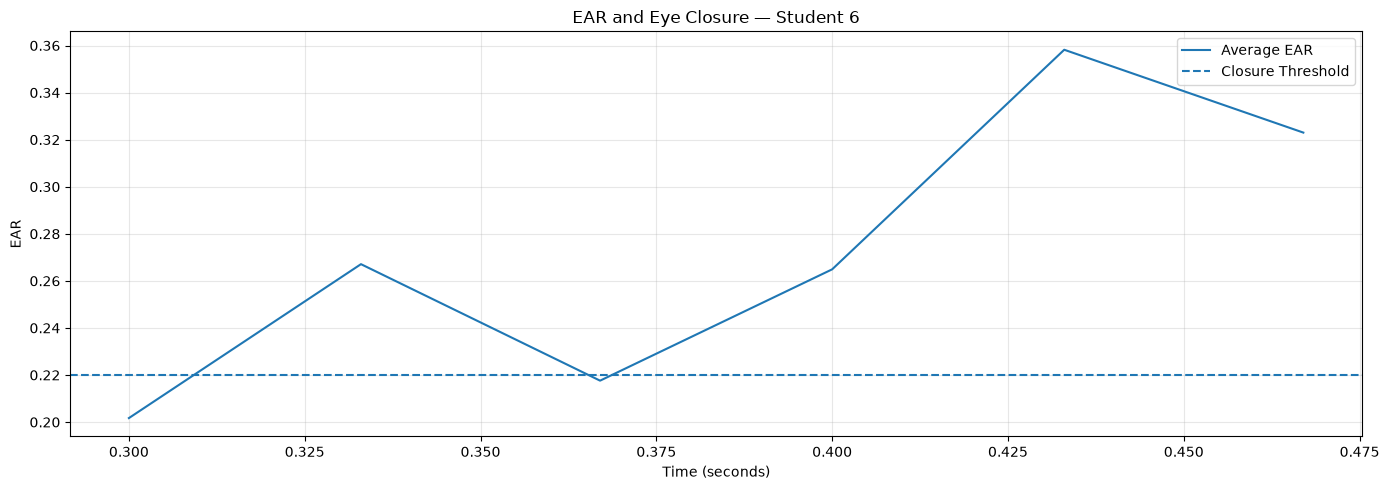

In [20]:
student_id = 6

student = df[df["student_id"] == student_id]

plt.figure(figsize=(14, 5))

plt.plot(
    student["time"],
    student["avg_ear"],
    label="Average EAR"
)

plt.axhline(
    y=0.22,
    linestyle="--",
    label="Closure Threshold"
)

plt.xlabel("Time (seconds)")
plt.ylabel("EAR")
plt.title(f"EAR and Eye Closure — Student {student_id}")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

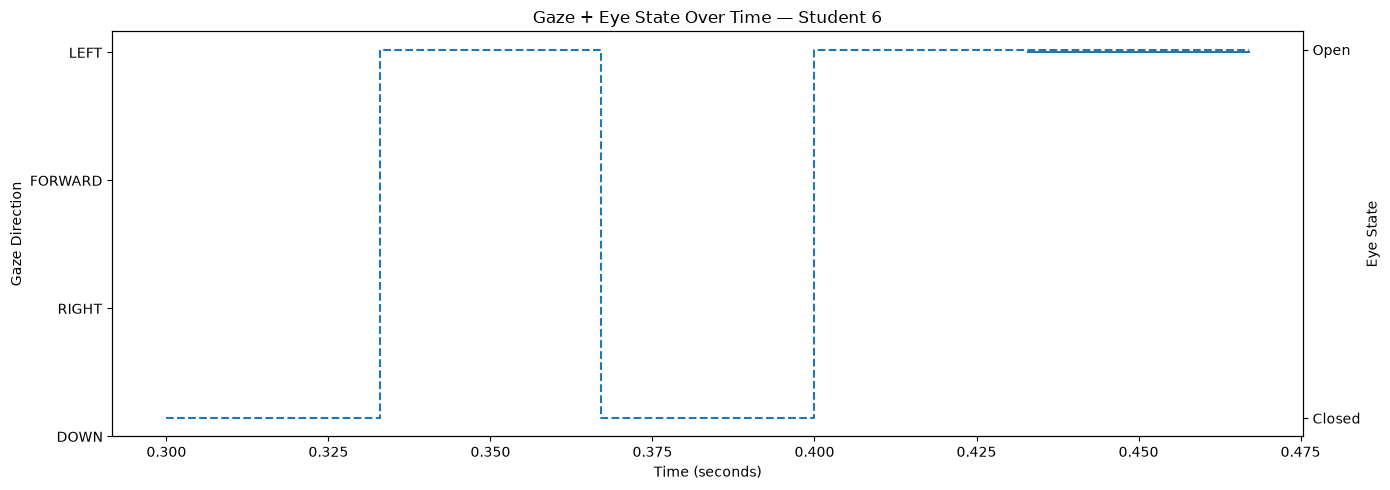

In [21]:
student_id = 6

student = df[df["student_id"] == student_id].copy()

gaze_mapping = {
    "DOWN": 0,
    "RIGHT": 1,
    "FORWARD": 2,
    "LEFT": 3
}

student["gaze_numeric"] = student["gaze"].map(gaze_mapping)

fig, ax1 = plt.subplots(figsize=(14, 5))

# Gaze
ax1.step(
    student["time"],
    student["gaze_numeric"],
    where="post",
    label="Gaze"
)

ax1.set_yticks([0, 1, 2, 3])
ax1.set_yticklabels(["DOWN", "RIGHT", "FORWARD", "LEFT"])
ax1.set_xlabel("Time (seconds)")
ax1.set_ylabel("Gaze Direction")

# Eye state on second axis
ax2 = ax1.twinx()

eye_numeric = student["eye_state"].map({
    "CLOSED": 0,
    "Closed": 0,
    "Open": 1,
    "OPEN": 1
})

ax2.step(
    student["time"],
    eye_numeric,
    where="post",
    linestyle="--",
    label="Eye State"
)

ax2.set_yticks([0, 1])
ax2.set_yticklabels(["Closed", "Open"])
ax2.set_ylabel("Eye State")

plt.title(f"Gaze + Eye State Over Time — Student {student_id}")
plt.tight_layout()
plt.show()

In [22]:
signal_availability = (
    df.groupby("student_id")
      .agg(
          head_pose_valid=("yaw", lambda x: x.notna().mean() * 100),
          eye_valid=("avg_ear", lambda x: x.notna().mean() * 100),
          gaze_valid=("gaze", lambda x: x.notna().mean() * 100),
          posture_valid=("torso_angle", lambda x: x.notna().mean() * 100)
      )
      .round(2)
)

signal_availability

,head_pose_valid,eye_valid,gaze_valid,posture_valid
student_id,,,,
1,43.80,59.69,43.80,100.00
2,51.76,73.33,51.76,98.04
3,68.22,72.90,68.22,93.46
4,27.45,31.37,27.45,91.18
6,33.33,100.00,33.33,0.00
8,0.00,0.00,0.00,0.00
9,55.88,85.29,55.88,0.00
12,20.00,40.00,20.00,0.00
17,0.00,18.75,0.00,93.75
